#Module End  Assignment: Python For Data Analysis


##Project Title: Social Media Engagement Analytics Using Python



###Task 1 — Data Import & Setup
- Import CSV using Pandas
- Check/convert data types
- Convert date columns to datetime
- Use NumPy arrays for basic array operations


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('social_media_engagement_5000.csv')

 The social media engagement dataset was loaded from a CSV file into a Pandas DataFrame named df.

In [ ]:
df.head(40)

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372
5,92386,16.0,Other,Canada,174310,video,tech,12535.0,1790.0,99.0,1427,24893,16-09-2023,684761,False,desktop,positive,#fitness,0.579440
6,47194,25.0,Male,Japan,481598,video,travel,11703.0,2276.0,1465.0,6287,96327,15-04-2022,519759,True,tablet,negative,#music,0.160329
7,97498,57.0,Female,Canada,343415,image,travel,9611.0,146.0,424.0,1699,68446,20-12-2023,698739,False,desktop,neutral,#travel #music #fitness,0.148745
8,54131,54.0,Female,UK,907449,image,fashion,NaN,2379.0,1897.0,5650,36283,06-07-2023,615809,True,desktop,negative,#music #fun #fitness,0.533914
9,70263,62.0,Female,Australia,495037,video,lifestyle,14106.0,2480.0,1053.0,3969,87972,16-11-2022,452146,False,tablet,neutral,#lifestyle #love,0.200507


In [ ]:
df.shape

(5000, 19)

it means the dataset contains 5,000 rows and 19 columns.

In [ ]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

In [ ]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


Displays the data type of each column.Some numerical columns, such as likes and age have the float64 data type

In [ ]:
df[['age', 'likes', 'comments', 'shares']].describe()

,age,likes,comments,shares
count,4850.000000,4850.000000,4850.000000,4850.000000
mean,38.454021,10107.043711,1502.195670,1002.629485
std,14.912381,5789.819252,869.537889,579.615158
min,13.000000,10.000000,0.000000,0.000000
25%,26.000000,5068.500000,760.000000,498.000000
50%,38.000000,10105.500000,1497.000000,1012.000000
75%,51.000000,15115.000000,2256.000000,1501.000000
max,64.000000,19998.000000,2999.000000,1999.000000


likes, comments, shares and age, have the float64  data type and they contain 150 missing values (better to change datatype after dealing with the missing values).

- Convert the date column

In [ ]:
df['posted_at'] = pd.to_datetime(df['posted_at'], dayfirst=True)
df['posted_at'].dtype


dtype('<M8[ns]')

pd.to_datetime() converts the posted_at column into a date and time data type. dayfirst=True tells Pandas to interpret dates with the day before the month when parsing ambiguous dates. The output datetime64[ns] confirms that the conversion was successful.

- Create a NumPy array

In [ ]:
likes_array = np.array(df['likes'])
likes_array[:10]

array([ 7011., 11750.,  4862.,  5350., 12682., 12535., 11703.,  9611.,
          nan, 14106.])

np.array() converts the likes column into a NumPy array. likes_array[:10] displays the first ten values. The nan value in your output represents a missing value. We are only observing it here; we are not cleaning it yet.

In [ ]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


The dataset 'social_media_engagement_5000.csv' was successfully imported using Pandas and contained 5,000 rows and 19 columns. The column names and data types were examined to understand the dataset structure. The posted_at column was converted to datetime format.

###Task 2 — Data Cleaning

 i - Cleaning Missing Data
- Detect missing values (isnull(), isna())
- Handle using: dropna(), fillna(), median/mode, forward/backward-fill

ii - Duplicate Handling
- Identify & remove duplicates

iii - Data Formatting
- Fix incorrect data types
- Standardize categories (e.g., gender labels)
- Correct unrealistic values in likes, comments, shares

iv - Feature Cleaning
- Extract hashtag count
- Clean sentiment labels


####i - Cleaning Missing Data

- Detect missing values (isnull(), isna())

- Handle using: dropna(), fillna(), median/mode, forward/backward-fill

In [ ]:
df.isnull().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


In [ ]:
df.isna().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


The isnull().sum() method was used to identify missing values in the dataset. The analysis revealed 150 missing values in each of the following columns: age, gender, likes, comments, shares, and sentiment. All other columns contained no missing values. The isna().sum() method was used to verify the missing-value counts. It produced the same results as isnull().sum(), confirming the presence of missing values in six columns.

In [ ]:
print("Median values:")
print(df[['age', 'likes', 'comments', 'shares']].median())

print("\nMode values:")
print("Gender:", df['gender'].mode()[0])
print("Sentiment:", df['sentiment'].mode()[0])

Median values:
age            38.0
likes       10105.5
comments     1497.0
shares       1012.0
dtype: float64

Mode values:
Gender: Male
Sentiment: positive


In [ ]:
missing_rows = df[df.isnull().any(axis=1)]

missing_rows.head(20)

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
8,54131,54.0,Female,UK,907449,image,fashion,NaN,2379.0,1897.0,5650,36283,2023-07-06,615809,True,desktop,negative,#music #fun #fitness,0.533914
17,74925,13.0,Male,Germany,980370,text,lifestyle,6704.0,2804.0,NaN,4394,63141,2023-05-01,212134,False,mobile,positive,#foodie #fun #lifestyle,0.181087
36,41551,NaN,Male,UAE,838360,text,fitness,5168.0,1486.0,1144.0,2750,12440,2022-09-17,562099,False,tablet,neutral,#music #lifestyle #love,0.626849
41,90038,29.0,NaN,UK,147547,video,food,19918.0,2859.0,1903.0,3043,73974,2023-01-18,133257,False,desktop,negative,#tech #fun #foodie,0.333631
48,33897,NaN,Female,USA,544056,video,music,2572.0,2777.0,267.0,2429,88819,2022-03-13,721632,False,desktop,neutral,#tech #music #foodie,0.063230
54,45920,42.0,Male,Germany,990766,text,education,NaN,860.0,1160.0,1531,30757,2022-10-04,143321,False,mobile,neutral,#love #fitness,0.388627
56,79479,60.0,Female,India,369861,reel,tech,NaN,1544.0,718.0,5174,14846,2023-07-28,133555,True,desktop,positive,#foodie #lifestyle #reels,0.274485
59,76557,31.0,NaN,USA,688310,video,music,8351.0,804.0,1420.0,3706,90167,2022-06-06,516878,False,mobile,positive,#reels #music #tech,0.117282
65,55758,56.0,NaN,USA,198039,text,education,11712.0,602.0,1599.0,1654,24821,2022-08-17,108929,False,tablet,positive,#foodie,0.560533
66,82409,43.0,Other,UAE,277452,text,education,6249.0,NaN,1349.0,4527,79887,2023-01-02,774779,False,tablet,negative,#travel #music,0.129946


In [ ]:
missing_rows = df[df.isnull().any(axis=1)]

missing_rows['missing_count'] = missing_rows.isnull().sum(axis=1)

missing_rows[['missing_count']].value_counts().sort_index()

/tmp/ipykernel_2850/557715611.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  missing_rows['missing_count'] = missing_rows.isnull().sum(axis=1)


,count
missing_count,
1,780
2,54
3,4


In [ ]:
df['age'] = df['age'].fillna(df['age'].median())
df['likes'] = df['likes'].fillna(df['likes'].median())
df['comments'] = df['comments'].fillna(df['comments'].median())
df['shares'] = df['shares'].fillna(df['shares'].median())

df['gender'] = df['gender'].fillna(df['gender'].mode()[0])
df['sentiment'] = df['sentiment'].fillna(df['sentiment'].mode()[0])

In [ ]:
print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


The `isnull().sum()` method was used to identify missing values in each column. The `isnull().any(axis=1)` condition helped identify rows containing missing values, while `sum(axis=1)` counted the missing entries in each row. The median was calculated for numerical columns (`age`, `likes`, `comments`, and `shares`), and the mode was identified for categorical columns (`gender` and `sentiment`). The `fillna()` method was then used to replace missing numerical values with their respective medians and categorical values with their modes. This approach addressed missing data while preserving all 5,000 records for further analysis.

ii - Duplicate Handling
- Identify & remove duplicates

In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


df.duplicated() identifies rows that are exact duplicates of earlier rows.
.sum() counts the duplicate rows. output shows 0 duplicate rows, so there are no exact duplicate records to remove. If there is duplicate raws we can use 'df = df.drop_duplicates()'.

####iii - Data Formatting
- Fix incorrect data types
- Standardize categories (e.g., gender labels)
- Correct unrealistic values in likes, comments, shares

- Fix incorrect data types

In [ ]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


In [ ]:
df['age'] = df['age'].round().astype(int)
df['likes'] = df['likes'].round().astype(int)
df['comments'] = df['comments'].round().astype(int)
df['shares'] = df['shares'].round().astype(int)

In [ ]:
df[['age', 'likes', 'comments', 'shares']].dtypes

,0
age,int64
likes,int64
comments,int64
shares,int64


The data types of the columns were checked. The `age`, `likes`, `comments`, and `shares` columns were converted to integers by rounding off the decimal values. This makes the data easier to use for further analysis.

- Standardize categories (e.g., gender labels)

In [ ]:
df['gender'].unique()


array(['Female', 'Male', 'Other'], dtype=object)

In [ ]:
print("Post Type:", df['post_type'].unique())
print("Post Category:", df['post_category'].unique())
print("Device Type:", df['device_type'].unique())
print("Sentiment:", df['sentiment'].unique())

Post Type: ['image' 'reel' 'text' 'video']
Post Category: ['fitness' 'food' 'tech' 'travel' 'fashion' 'lifestyle' 'education'
 'music']
Device Type: ['mobile' 'tablet' 'desktop']
Sentiment: ['negative' 'positive' 'neutral']


The unique values in the categorical columns were checked. The gender, post type, post category, device type, and sentiment values were consistent, so no changes were needed.

- Correct unrealistic values in likes, comments, shares

In [ ]:
df[['likes', 'comments', 'shares']].describe()

,likes,comments,shares
count,5000.000000,5000.000000,5000.0000
mean,10107.012400,1502.039800,1002.9106
std,5702.293014,856.393312,570.8552
min,10.000000,0.000000,0.0000
25%,5235.000000,792.000000,511.0000
50%,10106.000000,1497.000000,1012.0000
75%,14959.000000,2235.250000,1483.0000
max,19998.000000,2999.000000,1999.0000


In [ ]:
print("Negative likes:", (df['likes'] < 0).sum())
print("Negative comments:", (df['comments'] < 0).sum())
print("Negative shares:", (df['shares'] < 0).sum())

Negative likes: 0
Negative comments: 0
Negative shares: 0


There are no negative values in these three columns.Zero comments or shares can be valid. the maximum values aren't automatically unrealistic.  so no corrections were needed.

iv - Feature Cleaning
- Extract hashtag count
- Clean sentiment labels

- Extract hashtag count

In [ ]:
df['hashtags'].head(10)

,hashtags
0,#foodie #travel #love
1,#fitness
2,#foodie
3,#music #foodie #fun
4,#travel
5,#fitness
6,#music
7,#travel #music #fitness
8,#music #fun #fitness
9,#lifestyle #love


In [ ]:
df['hashtag_count'] = df['hashtags'].str.count('#')
df[['hashtags', 'hashtag_count']].head(10)

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


A new column named 'hashtag_count' was created to store the number of hashtags in each post. The hashtags were counted using the 'str.count()' method.

- Clean sentiment labels

In [ ]:
print("Unique sentiment values:", df['sentiment'].unique())
print("Missing sentiment values:", df['sentiment'].isnull().sum())

Unique sentiment values: ['negative' 'positive' 'neutral']
Missing sentiment values: 0


The sentiment column was checked for unique values and missing entries. The labels (negative, positive, and neutral) were already consistent, and no missing values were found. Therefore, no changes were needed.

###Task 3 — Data Exploration using Pandas
Perform the following:

- View dataset structure using head(), tail(), shape, and columns.
- Check data types and info with info() and dtypes.
- Generate summary statistics using describe().
- Analyze categorical distributions using value_counts(), unique(), and nunique().
- Create a correlation matrix for numeric fields.
- Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country).


- View dataset structure using head(), tail(), shape, and columns.

In [ ]:
print("First 5 rows:")
display(df.head())

print("Last 5 rows:")
display(df.tail())

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

First 5 rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32,Female,UK,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34,Other,UK,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


Last 5 rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44,Male,Australia,441541,video,education,16210,2013,1837,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38,Other,UAE,677076,reel,education,16924,2734,1583,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63,Female,USA,273595,text,travel,13487,1497,167,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54,Other,Japan,712252,text,travel,14830,503,1798,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3



Dataset shape: (5000, 20)

Column names:
Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='object')


The first five and last five rows of the dataset were displayed using head() and tail(). The shape attribute was used to check the number of rows and columns, and columns was used to view the column names.

- Check data types and info with info() and dtypes.

In [ ]:
df.info()

print("\nData types:")
print(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

The 'info()' and 'dtypes' methods were used to check the dataset information and data types. The dataset contains 5,000 rows and 20 columns, with no missing values remaining. The columns contain different data types, including integers, floats, text, Boolean values, and datetime values.

- Generate summary statistics using describe().

In [ ]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10107.012400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10106.000000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293014,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


The 'describe()' method was used to generate summary statistics for the numerical columns. It displayed the count, mean, standard deviation, minimum, maximum, and quartiles. These statistics helped us understand the distribution of values in the dataset. Mean: The average age is approximately 38 years. Median: Half of the posts have 10,106 likes or fewer, and half have 10,106 likes or more. Minimum and maximum: These show the smallest and largest values in each column.

- Analyze categorical distributions using value_counts(), unique(), and nunique().

In [ ]:
print("Post Type Distribution:")
print(df['post_type'].value_counts())

Post Type Distribution:
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64


It counts how many times each category appears. here, it tells us how many image, reel, text, and video posts are in the dataset.

In [ ]:
print("Unique post categories:")
print(df['post_category'].unique())

Unique post categories:
['fitness' 'food' 'tech' 'travel' 'fashion' 'lifestyle' 'education'
 'music']


In [ ]:
print("\nNumber of unique post categories:")
print(df['post_category'].nunique())


Number of unique post categories:
8


The 'unique()' method was used to display the different post categories in the dataset. The output showed eight categories: fitness, food, tech, travel, fashion, lifestyle, education, and music. The 'nunique()' method returned 8, confirming that the dataset contains eight unique post categories.

- Create a correlation matrix for numeric fields.


In [ ]:
numeric_df = df.select_dtypes(include='number')
correlation_matrix = numeric_df.corr()
correlation_matrix

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014527,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014527,1.000000,-0.018421,0.004712,0.008711,0.007952,-0.022982,0.093520,-0.002189
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008711,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


Correlation is a statistical measure used to identify the relationship between two numerical variables. It helps us understand whether two variables tend to increase together, move in opposite directions, or have little linear relationship. df.select_dtypes(include='number') - Selects all numerical columns from the dataset. numeric_df - Stores the selected numerical columns.numeric_df.corr() - Calculates the correlation coefficients between pairs of numerical columns using Pearson correlation. correlation_matrix - Stores the resulting correlation matrix and displays the matrix.

- Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country).


In [ ]:
df.groupby('post_type')['likes'].mean()

,likes
post_type,
image,10104.878107
reel,10037.819953
text,10100.163855
video,10188.613878


The groupby() method in Pandas was used to summarize social media engagement metrics. Here , The groupby() method groups the dataset by post_type. The "['likes']" selects the likes column, and the mean() method calculates the average likes for each post type. This helps compare the average likes received by images, reels, text posts, and videos.

###Task 4 — Data Wrangling
- Use merge, concat, or join if combining DataFrames.
- Create new fields such as engagement_score, log-transformed metrics (optional), and hashtag_count.
- Perform groupby summaries by post_type, country, and sentiment.


- Use merge, concat, or join if combining DataFrames.

In [ ]:
likes_df = df[['post_id', 'likes']]
comments_df = df[['post_id', 'comments']]

merged_df = pd.merge(likes_df, comments_df, on='post_id')

merged_df.head()

,post_id,likes,comments
0,496713,7011,354
1,157326,11750,2606
2,109864,4862,344
3,848877,5350,1083
4,449706,12682,2735


In [ ]:
print("Original dataset shape:", df.shape)
print("Merged dataset shape:", merged_df.shape)
print("Unique post IDs:", df['post_id'].nunique())

Original dataset shape: (5000, 20)
Merged dataset shape: (5018, 3)
Unique post IDs: 4991


The merge() function in Pandas was used to combine two DataFrames using the common column post_id. One DataFrame contained post IDs and likes, while the other contained post IDs and comments. The resulting DataFrame combines these engagement metrics, allowing likes and comments to be analyzed together for each post.

- Create new fields such as engagement_score, log-transformed metrics (optional), and hashtag_count.

In [ ]:
df['engagement_score'] = df['likes'] + df['comments'] + df['shares']

df[['likes', 'comments', 'shares', 'engagement_score']].head()

,likes,comments,shares,engagement_score
0,7011,354,1157,8522
1,11750,2606,1807,16163
2,4862,344,955,6161
3,5350,1083,1049,7482
4,12682,2735,1300,16717


A new column named 'engagement_score' was created by adding the values of 'likes', 'comments, and 'shares' for each record. This column represents the total number of interactions recorded for each row. Here, the first row has 7,011 likes, 354 comments, and 1,157 shares, resulting in an engagement score of 8,522. This new feature helps analyze and compare engagement across the dataset.

In [ ]:
df['hashtag_count'] = df['hashtags'].str.count('#')

In [ ]:
df['log_likes'] = np.log1p(df['likes'])
df[['likes', 'log_likes']].head()

,likes,log_likes
0,7011,8.855378
1,11750,9.371694
2,4862,8.489411
3,5350,8.585039
4,12682,9.448018


np.log1p(df['likes']) calculates the natural logarithm of one plus each likes value. df['log_likes'] stores the transformed values in a new column.
.head() displays the first five rows for comparison.

Here a new column named 'log_likes' was created using NumPy's 'log1p()' function to apply a natural logarithmic transformation to the likes values. This transformation reduces the effect of very large values and can help when analyzing skewed data. Since this step is optional, it was included as an additional data-wrangling operation.

A new column named hashtag_count was created using the str.count() method to count the number of hashtags in each post

In [ ]:
df.groupby('post_type')['engagement_score'].mean()

,engagement_score
post_type,
image,12649.403368
reel,12524.049104
text,12613.259438
video,12664.608163


average engagement score for each post type, helping us compare the engagement of images, reels, text posts, and videos.

In [ ]:
df.groupby('country')['impression_count'].sum()

,impression_count
country,
Australia,23834767
Brazil,24793360
Canada,24984716
France,25656926
Germany,23816649
India,28067377
Japan,23418816
UAE,24610992
UK,25201861


In [ ]:
df.groupby('sentiment')['engagement_score'].mean()

,engagement_score
sentiment,
negative,12731.514583
neutral,12448.178127
positive,12665.814564


The 'groupby()' method in Pandas was used to summarize social media engagement data by 'post_type', 'country', and 'sentiment'. First, the average engagement score was calculated for each post type using the 'mean()' function. Videos recorded the highest average engagement score (12,664.61), while reels recorded the lowest (12,524.05). Next, the total impressions for each country were calculated using the `sum()` function. Among the visible results, India recorded 28,067,377 impressions, while Japan recorded 23,418,816. Finally, the average engagement score was calculated for each sentiment category. Negative sentiment had the highest average engagement score (12,731.51), followed by positive sentiment (12,665.81) and neutral sentiment (12,448.18). These summaries help compare engagement across different post types and sentiment categories and examine content reach across countries.

###Task 5 — Statistical Analysis
Compute descriptive stats for likes, comments, shares, watch_time, engagement_rate, followers:
- Mean, median, mode
- Standard deviation, variance
- Percentiles
- (Optional) Skewness and kurtosis


In [ ]:
print("Mean:", df['likes'].mean())
print("Median:", df['likes'].median())
print("Mode:", df['likes'].mode())

Mean: 10107.0124
Median: 10106.0
Mode: 0    10106
Name: likes, dtype: int64


In [ ]:
columns = ['likes', 'comments', 'shares','watch_time_sec', 'engagement_rate','follower_count']

for col in columns:
    print("\nColumn:", col)
    print("\nMean:", df[col].mean())
    print("\nMedian:", df[col].median())
    print("\nMode:", df[col].mode())
    print("\nStandard Deviation:", df[col].std())
    print("\nVariance:", df[col].var())
    print("\nPercentiles:")
    print(df[col].quantile([0.25, 0.50, 0.75]))


Column: likes

Mean: 10107.0124

Median: 10106.0

Mode: 0    10106
Name: likes, dtype: int64

Standard Deviation: 5702.293013882179

Variance: 32516145.616169512

Percentiles:
0.25     5235.0
0.50    10106.0
0.75    14959.0
Name: likes, dtype: float64

Column: comments

Mean: 1502.0398

Median: 1497.0

Mode: 0    1497
Name: comments, dtype: int64

Standard Deviation: 856.3933120458967

Variance: 733409.5049169405

Percentiles:
0.25     792.00
0.50    1497.00
0.75    2235.25
Name: comments, dtype: float64

Column: shares

Mean: 1002.9106

Median: 1012.0

Mode: 0    1012
Name: shares, dtype: int64

Standard Deviation: 570.8551999758862

Variance: 325875.65933950903

Percentiles:
0.25     511.0
0.50    1012.0
0.75    1483.0
Name: shares, dtype: float64

Column: watch_time_sec

Mean: 4014.5032

Median: 4034.5

Mode: 0     916
1    2145
2    4360
3    7003
4    7688
Name: watch_time_sec, dtype: int64

Standard Deviation: 2308.096459042085

Variance: 5327309.26424261

Percentiles:
0.25    2

The columns list contains six numerical columns selected for statistical analysis: likes, comments, shares, watch_time_sec, engagement_rate, and follower_count. A for loop iterates through each column and calculates the required statistical measures using Pandas methods.
mean() calculates the average value. median() finds the middle value of the data. mode() identifies the most frequently occurring value. std() calculates the standard deviation, which measures how spread out the values are around the mean. var() calculates the variance, which measures the variability of the data .quantile([0.25, 0.50, 0.75]) calculates the 25th, 50th, and 75th percentiles to understand the distribution of values.

###Task 6 — Data Visualization
Matplotlib
- Scatter: likes vs impressions
- Line: daily engagement trend
- Bar: posts by category
- Pie: gender distribution
- Histogram: age
- Box: engagement rate


- Scatter: likes vs impressions

In [ ]:
import matplotlib.pyplot as plt

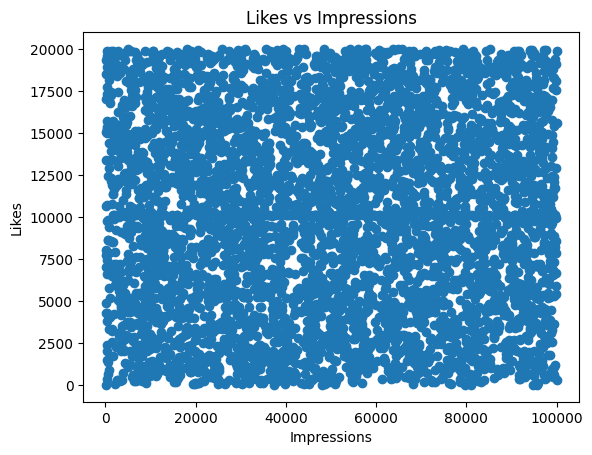

In [ ]:
plt.scatter(df['impression_count'], df['likes'])
plt.title('Likes vs Impressions')
plt.xlabel('Impressions')
plt.ylabel('Likes')
plt.show()

A scatter plot was created using Matplotlib to visualize the relationship between impression_count and likes. plt.scatter() creates a scatter plot to show the relationship between two numerical variables. df['impression_count'] represents the number of impressions and is displayed on the X-axis.df['likes'] represents the number of likes and is displayed on the Y-axis.lt.title() adds a title to the graph.plt.xlabel() and plt.ylabel() label the axes. plt.show() displays the plot.

- Line: daily engagement trend

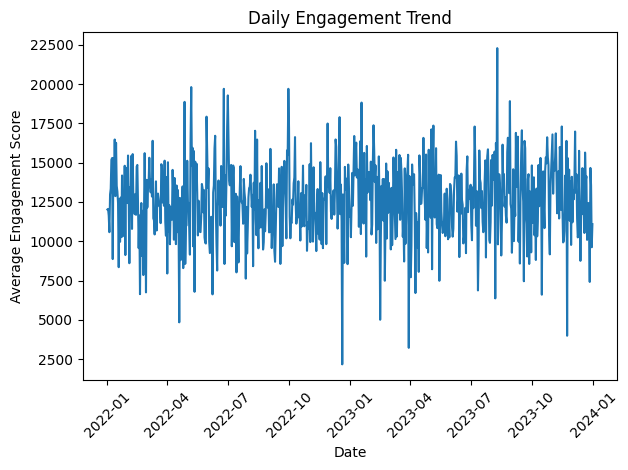

In [ ]:
import matplotlib.pyplot as plt

daily_engagement = df.groupby(df['posted_at'].dt.date)['engagement_score'].mean()

plt.plot(daily_engagement.index, daily_engagement.values)
plt.title('Daily Engagement Trend')
plt.xlabel('Date')
plt.ylabel('Average Engagement Score')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

A line chart was created using Matplotlib to visualize the daily engagement trend. df.groupby(df['posted_at'].dt.date) — groups posts by their posting date.['engagement_score'].mean() — calculates the average engagement score for each day.plt.plot() — creates the line chart to show changes over time.plt.xticks(rotation=45) — rotates date labels so they're easier to read. plt.tight_layout() — adjusts the layout to prevent labels from overlapping. Most values remain around 10,000–15,000, with a few noticeable peaks and drops. No clear overall upward or downward trend is visible during the period. This visualization helps examine how social media engagement changes over time.

- Bar: posts by category

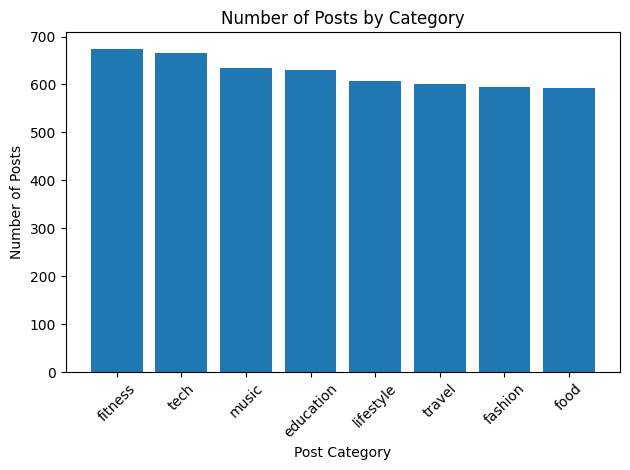

In [ ]:
import matplotlib.pyplot as plt

category_counts = df['post_category'].value_counts()
plt.bar(category_counts.index, category_counts.values)
plt.title('Number of Posts by Category')
plt.xlabel('Post Category')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

A bar chart was created using Matplotlib to compare the number of social media posts across different categories. value_counts() counts the number of posts in each category. plt.bar() creates the bar chart. category_counts.index provides the category names for the X-axis. category_counts.values provides the number of posts for the Y-axis. plt.xticks(rotation=45) rotates the category labels for readability.  Fitness has the highest number of posts, while Food has the lowest. The remaining categories have relatively similar post counts. Overall, the dataset shows a fairly balanced distribution of posts across categories.

- Pie: gender distribution

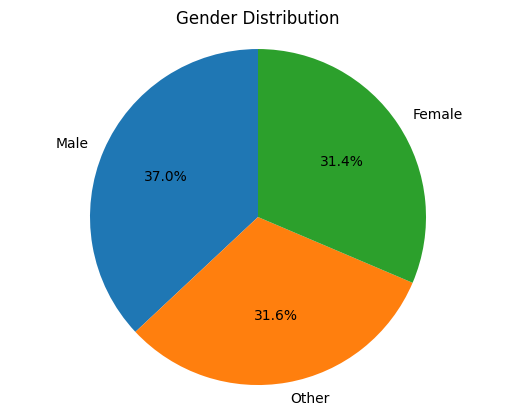

In [ ]:
import matplotlib.pyplot as plt

gender_counts = df['gender'].value_counts()
plt.pie( gender_counts.values,labels=gender_counts.index,autopct='%1.1f%%',startangle=90)
plt.title('Gender Distribution')
plt.axis('equal')
plt.show()

A pie chart was created using Matplotlib to visualize the gender distribution in the dataset. value_counts() counts the records in each gender category. plt.pie() creates the pie chart. labels=gender_counts.index displays the gender categories. autopct='%1.1f%%' displays each category's percentage to one decimal place. startangle=90 rotates the chart to position the first slice appropriately. plt.axis('equal') keeps the pie chart circular. Here , male records account for 37.0%, Other accounts for 31.6%, and Female accounts for 31.4%. Male is the largest category, while Female is the smallest. The distribution is relatively balanced across the three categories.

- Histogram: age

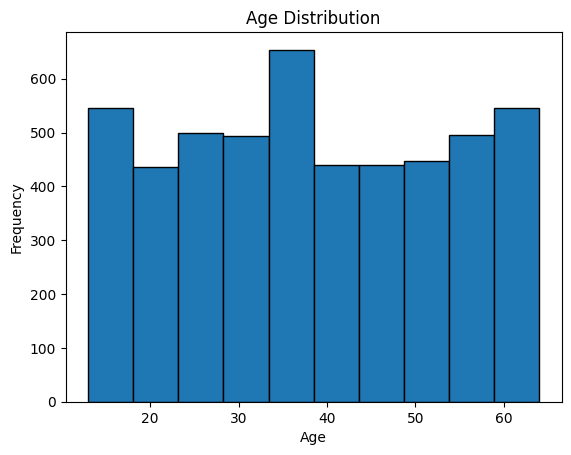

In [ ]:
plt.hist(df['age'], bins=10, edgecolor='black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

A histogram was created using Matplotlib to visualize the age distribution of users in the dataset.plt.hist() creates a histogram to show the distribution of ages. df['age'] provides the age data. bins=10 divides the age range into 10 intervals. edgecolor='black' adds borders to the bars so they are easier to distinguish. The X-axis represents age intervals, and the Y-axis represents the number of records in each interval. Here ,the ages range approximately from 13 to 64 years. The interval around 33-38 has the highest frequency, while several other age intervals also contain substantial numbers of users. Overall, the users are distributed across a broad range of ages.

- Box: engagement rate

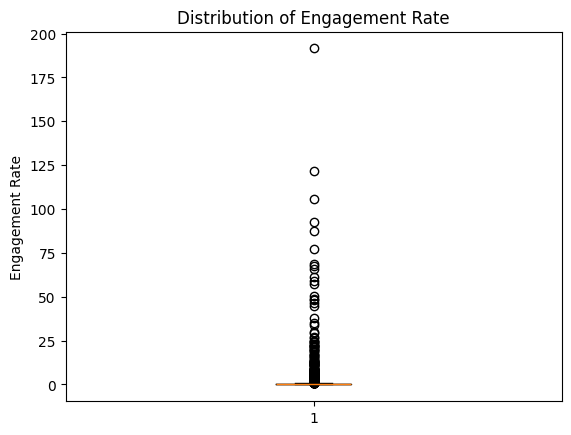

In [ ]:
plt.boxplot(df['engagement_rate'])
plt.title('Distribution of Engagement Rate')
plt.ylabel('Engagement Rate')
plt.show()

A box plot was created using Matplotlib to visualize the distribution of engagement rates. plt.boxplot() creates a box plot to summarize the distribution of engagement rates. The box represents the middle 50% of the data, between the first and third quartiles. The line inside the box represents the median. The whiskers show the range of values within the box plot's whisker limits. Individual points beyond the whiskers may indicate potential outliers. Here, this box plot shows that engagement rates are concentrated near the lower end of the distribution. Several potential outliers appear above the upper whisker, including an extreme value of approximately 192. The distribution appears strongly right-skewed, indicating that a small number of observations have much higher engagement rates than most of the dataset.

####Seaborn
- Count plot: post type
- Bar plot: avg likes by category
- Violin: followers vs sentiment
- Pair plot: numeric features
- Heatmap: correlation matrix
- Swarm plot: engagement vs device


- Count plot: post type

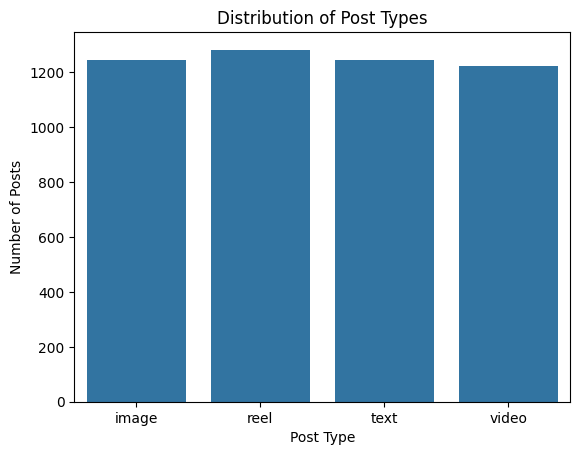

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='post_type')
plt.title('Distribution of Post Types')
plt.xlabel('Post Type')
plt.ylabel('Number of Posts')
plt.show()

A count plot was created using Seaborn to visualize the distribution of post types in the dataset. The countplot() function counts how many records belong to each post_type category and displays the results as bars.The graph shows that Reels have the highest number of posts, while Videos have the lowest. However, the differences are relatively small, indicating a fairly balanced distribution of post types in the datase

- Bar plot: avg likes by category

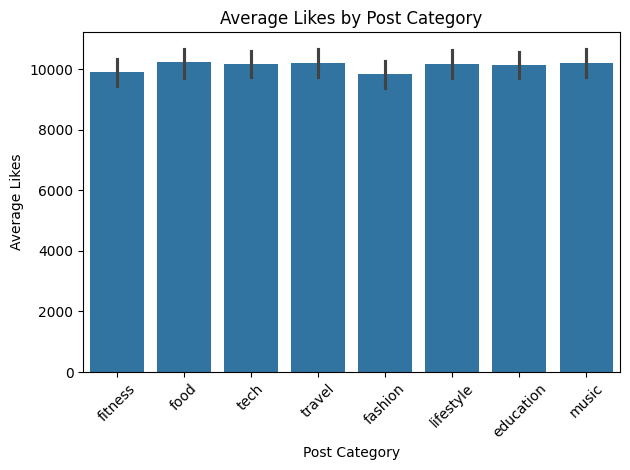

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(data=df, x='post_category', y='likes')
plt.title('Average Likes by Post Category')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

A bar plot was created using Seaborn to compare the average number of likes across different post categories.  sns.barplot() creates a bar chart showing the mean value of a numerical variable for each category by default.
x='post_category' displays the content categories on the X-axis. y='likes' calculates and displays the average likes for each category. plt.xticks(rotation=45) rotates the category labels to make them easier to read. plt.tight_layout() adjusts the spacing. The results show that Food and Travel have slightly higher average likes, while Fashion has the lowest average. However, the differences between categories are relatively small, indicating similar average like counts across the categories.

- Violin: followers vs sentiment

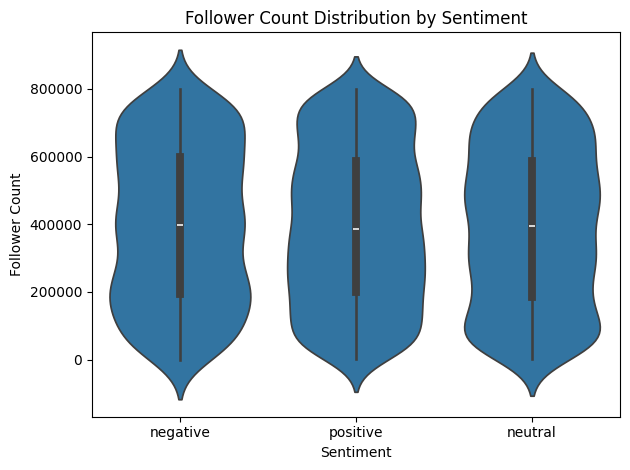

In [ ]:
sns.violinplot(data=df, x='sentiment', y='follower_count')

plt.title('Follower Count Distribution by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')
plt.tight_layout()
plt.show()

A violin plot was created using Seaborn to compare the distribution of follower counts across negative, positive, and neutral sentiment groups. The neutral sentiment group appears to have the highest median follower count, while the positive group has a slightly lower median. All three groups show a wide distribution of follower counts, with considerable overlap between them.

- Pair plot: numeric features

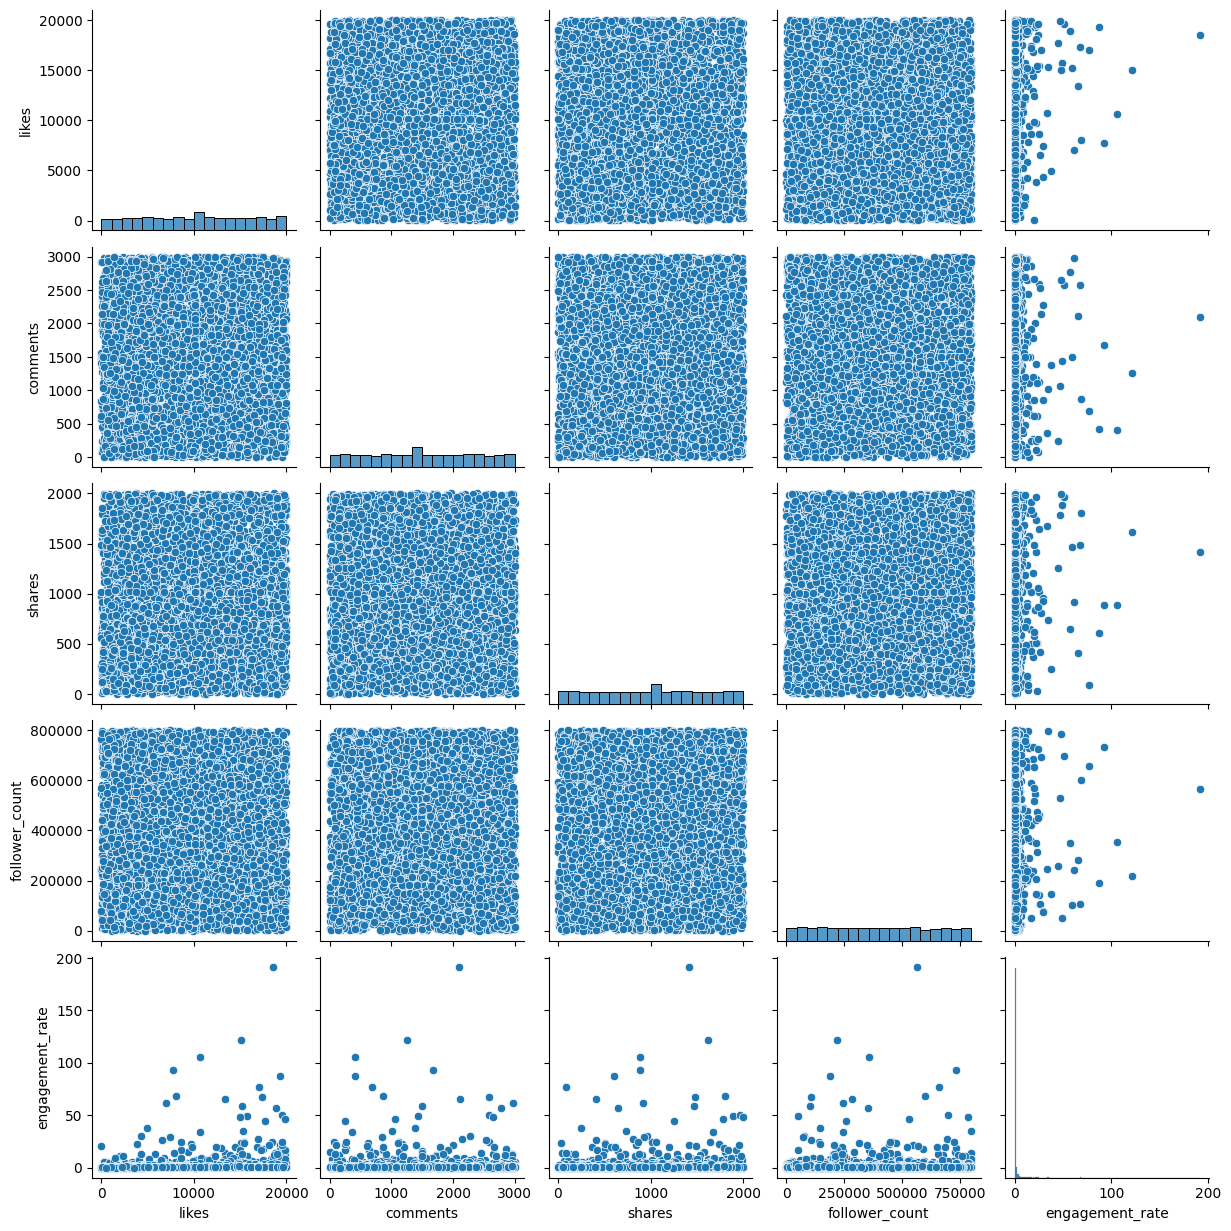

In [ ]:
numeric_features = ['likes','comments','shares','follower_count','engagement_rate']
sns.pairplot(df[numeric_features])
plt.show()

A pair plot was created using Seaborn to examine the distributions of numerical variables and the relationships between them. The plots involving engagement rate show that most observations have relatively low values, while a few observations have unusually high engagement rates.

- Heatmap: correlation matrix


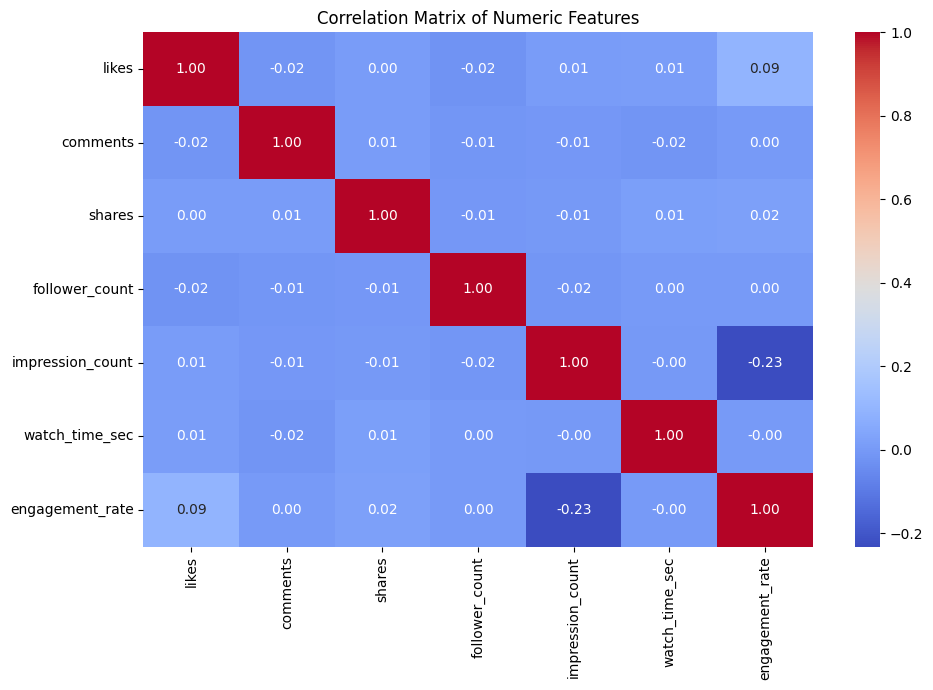

In [ ]:
numeric_features = [ 'likes','comments','shares','follower_count','impression_count','watch_time_sec', 'engagement_rate']

correlation_matrix = df[numeric_features].corr()
plt.figure(figsize=(10, 7))

sns.heatmap( correlation_matrix,annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Correlation Matrix of Numeric Features')
plt.tight_layout()
plt.show()

A correlation heatmap was created using Seaborn to examine the linear relationships between numerical features, including likes, comments, shares, follower count, impression count, watch time, and engagement rate. The strongest relationship with engagement rate is a weak negative correlation with impression count (-0.23). Likes show a very weak positive correlation with engagement rate (0.09), while most other variable pairs have correlations close to zero. These results suggest that the numerical variables generally have weak linear relationships in this dataset.

- Swarm plot: engagement vs device

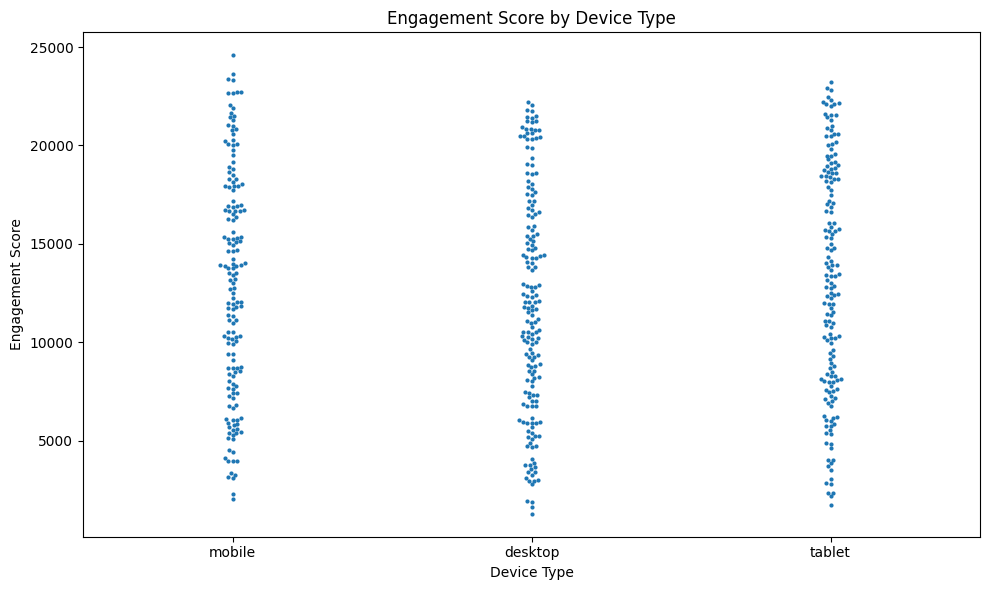

In [ ]:
plt.figure(figsize=(10, 6))

sns.swarmplot(data=df.sample(n=500, random_state=42), x='device_type', y='engagement_score', size=3)
plt.title('Engagement Score by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Engagement Score')
plt.tight_layout()
plt.show()

A swarm plot was created using Seaborn to compare engagement scores across mobile, desktop, and tablet devices. The plot shows a wide distribution of engagement scores for all three device types. Mobile and tablet posts reach slightly higher maximum scores than desktop posts in the selected sample. However, the distributions overlap considerably, so the plot alone does not establish which device type has the highest overall engagement. I previously created engagement_score column using likes + comments + shares
It gives us a combined measure of engagement.

**Plotly (Interactive)**

Interactive line chart/bar chart/bubble/scatter chart

- scatter chart

In [ ]:
import plotly.express as px

fig = px.scatter( df,x='impression_count',y='likes',color='post_type')
fig.show()

An interactive scatter plot was created using Plotly Express to explore the relationship between impression count and likes. The X-axis represents impressions, while the Y-axis represents likes.Different colours represent image, reel, text, and video posts.  The graph shows a wide distribution of likes across different impression counts, with no clear visual relationship between the two variables. Interactive features allow users to hover over data points and explore individual observations.

- bar chart

In [ ]:
import plotly.express as px

avg_likes = df.groupby('post_category', as_index=False)['likes'].mean()

fig = px.bar(avg_likes,x='post_category', y='likes',title='Average Likes by Post Category',
             labels={'post_category': 'Post Category','likes': 'Average Likes'})

fig.show()

An interactive bar chart was created using Plotly Express to compare average likes across different post categories. The chart shows that Food has the highest average likes, while Fashion has the lowest. However, the differences between categories are relatively small. The interactive features allow users to explore and compare the average likes for each category.

####Content Performance

- Which post types have highest engagement?

In [ ]:
engagement_by_type = df.groupby('post_type')['engagement_score'].mean()
print(engagement_by_type.sort_values(ascending=False))

groupby('post_type')	Groups posts by image, reel, text, and video['engagement_score'].mean()	Calculates the average engagement score for each type. sort_values(ascending=False)	Displays the results from highest to lowest. Here, video has the highest average engagement score (12,664.608), while Reel has the lowest (12,524.049).

- Best-performing content category?

In [ ]:
engagement_by_category = df.groupby('post_category')['engagement_score'].mean()
print(engagement_by_category.sort_values(ascending=False))

groupby('post_category') groups posts by category, such as Food, Fitness, and Technology. mean() calculates the average engagement score for each category. sort_values(ascending=False) displays the categories from highest to lowest average engagement. Here, Music performed best, with an average engagement score of 12,788.56, followed by Food at 12,739.22. Fashion had the lowest average engagement score at 12,356.44. These results indicate that Music content generates the highest average combined engagement of likes, comments, and shares in this dataset.

- Which countries have highest avg engagement rate?


In [ ]:
engagement_by_country = ( df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False))
print(engagement_by_country.head(10))

The average engagement rate was calculated for each country and sorted in descending order. Brazil recorded the highest average engagement rate at 1.540704, followed by Australia at 1.324339 and France at 1.146402. Among the ten countries displayed, the USA had the lowest average at 0.576580. These results show differences in average engagement rates across countries in the dataset.

####User Trends


- How age affects engagement


In [ ]:
df.groupby('age')['engagement_score'].mean().sort_values(ascending=False)

Age 49 - Has the highest average engagement score shown, approximately 1416221.Age 17 - Has an average engagement score of approximately 14,156.46.
Age 33 - Has an average engagement score of approximately 13,796.28.
Age 14 -  Has an average engagement score of approximately 13,469.03.
The results show variations in average engagement across different ages. Among the values visible in the output, users aged 49 have the highest average engagement score, approximately.

In [ ]:
import pandas as pd

df['age_group'] = pd.cut( df['age'], bins=[0, 18, 25, 35, 45, 55, 100],labels=['Under 18', '18–25', '26–35', '36–45', '46–55', '56+'])

engagement_by_age = (df.groupby('age_group', observed=False)['engagement_score'].mean().sort_values(ascending=False))
print(engagement_by_age)

Another code for this . pd.cut() divides numerical values into groups, also called bins. Instead of analysing every age separately, we can compare broader age groups. bins=[0, 18, 25, 35, 45, 55, 100] - These numbers define the boundaries of the age groups. Labels are the names assigned to the groups.

 The average engagement score was calculated for different age groups. Users under 18 recorded the highest average engagement score of 12,991.73, followed by users aged 26–35 at 12,768.72. The 56+ age group had the lowest average engagement score at 12,261.76. These findings indicate that average engagement varies across age groups in the dataset.

- Performance difference for verified accounts

In [ ]:
df.groupby('is_verified')['engagement_score'].mean()

Non-verified accounts have the higher average engagement score of 12,644.33.
Verified accounts have a lower average engagement score of 12,309.29.
The difference is approximately 335.03 .

####Behavioral Insights


- Best time of day for impressions


In [ ]:
df['posted_at'].head(10)

,posted_at
0,2022-12-17
1,2023-06-02
2,2023-05-07
3,2023-02-12
4,2023-05-23
5,2023-09-16
6,2022-04-15
7,2023-12-20
8,2023-07-06
9,2022-11-16


In [ ]:
df.groupby(df['posted_at'].dt.hour)['impression_count'].mean()

,impression_count
posted_at,
0,50013.7328


df['posted_at']	Selects the posted_at column. .dt.hour	Extracts the hour from the posting date and time. groupby()	Groups the posts according to their posting hour. ['impression_count']	Selects the impression count column. .mean()	Calculates the average impressions for each hour.The posting time was examined to identify the time of day associated with the highest impressions. However, the posted_at column in the dataset contains only dates and does not include specific posting hours or minutes. Therefore, it is not possible to determine the best time of day for impressions using the available data.

- Device type impact on watch time

In [127]:
df.groupby('device_type')['watch_time_sec'].mean()

,watch_time_sec
device_type,
desktop,3974.792521
mobile,4087.830760
tablet,3979.736429


groupby('device_type')	Groups the data according to device type['watch_time_sec']	Selects the watch-time column. .mean()	Calculates the average watch time for each device. so here ,the average watch time was calculated for each device type using Pandas. Mobile users recorded the highest average watch time of 4,087.83 seconds, followed by tablet users at 3,979.74 seconds and desktop users at 3,974.79 seconds. These results indicate that mobile devices have the highest average watch time in the dataset.

####Sentiment Analysis

- Which sentiment performs best


In [128]:
df.groupby('sentiment')['engagement_score'].mean()

,engagement_score
sentiment,
negative,12731.514583
neutral,12448.178127
positive,12665.814564


groupby('sentiment')	Groups posts by positive, negative, and neutral sentiment. ['engagement_score']	Selects the engagement score column. .mean() Calculates the average engagement score for each sentiment.Here, the average engagement score was calculated for positive, negative, and neutral posts. Negative sentiment posts recorded the highest average engagement score of 12,731.51, followed by positive posts at 12,665.81. Neutral posts had the lowest average engagement score of 12,448.18. Therefore, negative sentiment posts showed the highest average engagement in the dataset

- Behavior of negative/neutral sentiment posts


In [129]:
df.groupby('sentiment')[['likes', 'comments', 'shares']].mean()

,likes,comments,shares
sentiment,,,
negative,10208.112500,1516.094792,1007.307292
neutral,9923.208906,1528.404060,996.565160
positive,10180.077199,1480.650617,1005.086749


groupby('sentiment')	Groups posts into positive, negative, and neutral categories. [['likes', 'comments', 'shares']]	Selects three engagement-related columns. .mean()	Calculates the average likes, comments, and shares for each sentiment.
Here, the average likes, comments, and shares were compared across different sentiment categories. Negative sentiment posts recorded the highest average likes (10,208.11) and shares (1,007.31). Neutral sentiment posts received the highest average comments (1,528.40), but had the lowest average likes and shares. Positive sentiment posts ranked second in average likes and shares. These results show that audience interaction varies across sentiment categories.